In [1]:
from eval import tracs_rate_scenario, show_comparison_study, compute_argoverse2_metrics
from pathlib import Path
import pandas as pd
import time
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def get_worst(metrics_path: str, n_head=36):
    metrics_df = pd.read_parquet(metrics_path)
    print("before filtering:", len(metrics_df))
    metrics_df = metrics_df[(metrics_df["is_missed_prediction1"]) & (
        ~metrics_df["is_missed_prediction6"])]
    print("after filtering:", len(metrics_df))
    return metrics_df.sort_values("brier_minADE6", ascending=False).head(n_head)

data_root = Path("../dataset")
backbone = "DeMo"
number_of_tests = 10
prediction_path = data_root / f"{backbone}_submission.parquet"
backbone_metrics_path = data_root / f"{backbone}_metrics.parquet"
results_path = data_root / "results" / backbone
worst = get_worst(backbone_metrics_path)

before filtering: 24984
after filtering: 10718


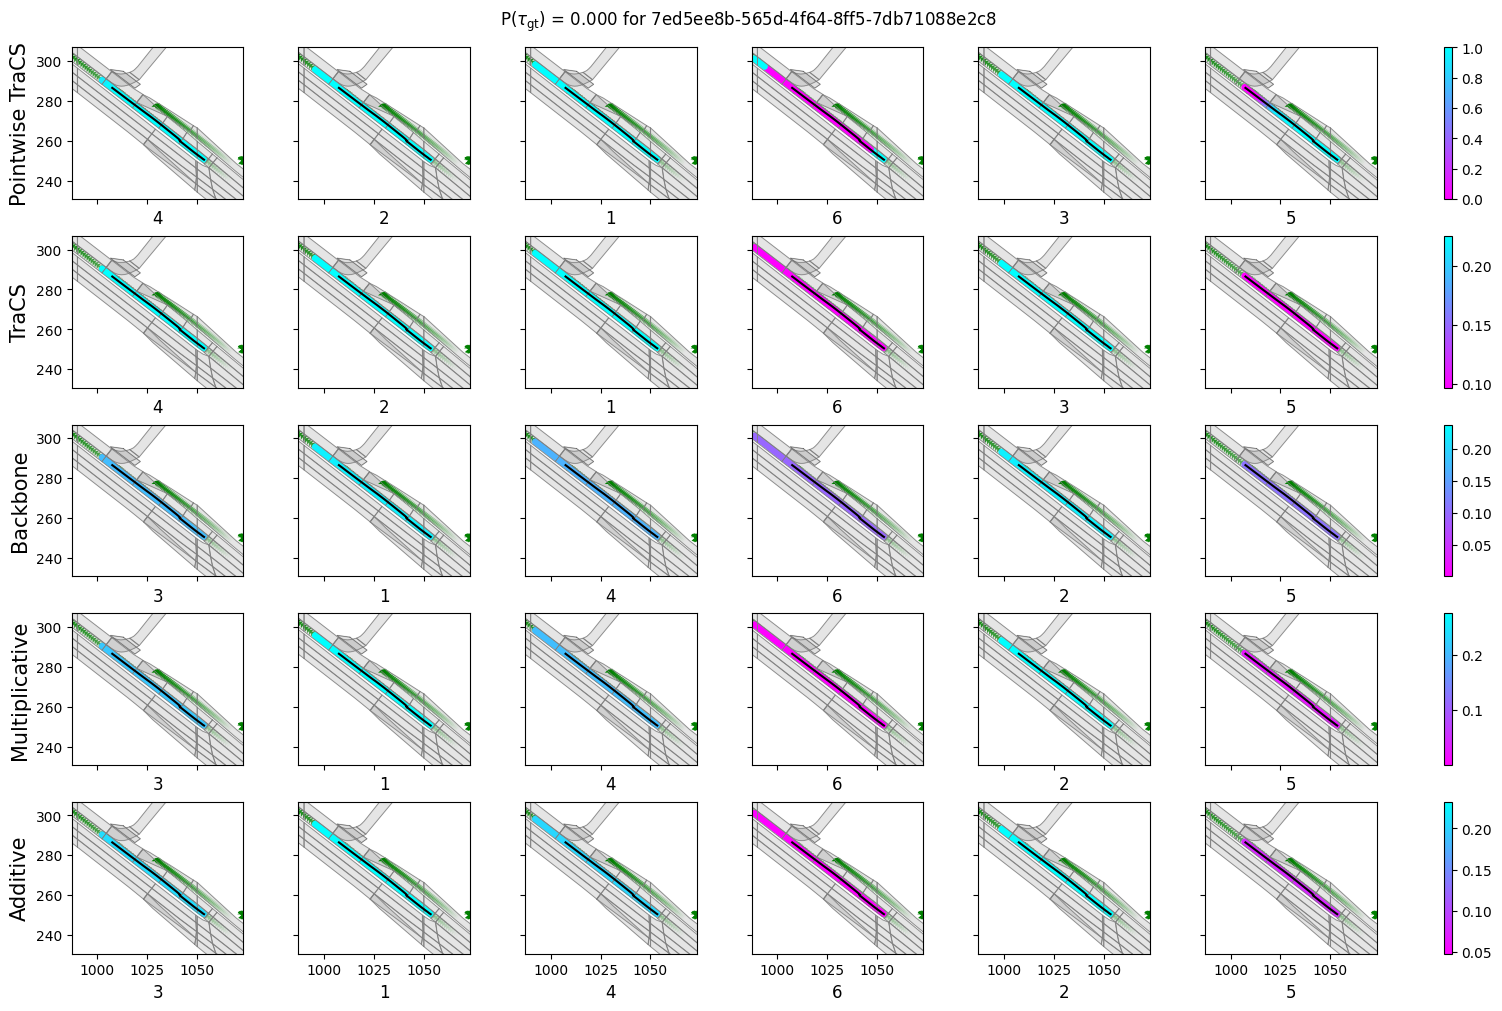

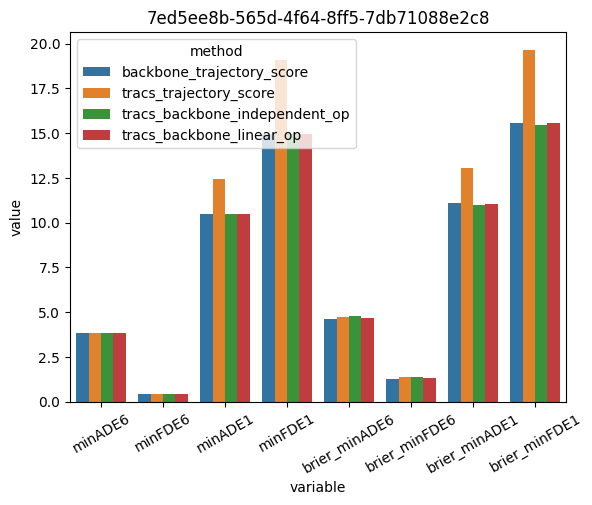

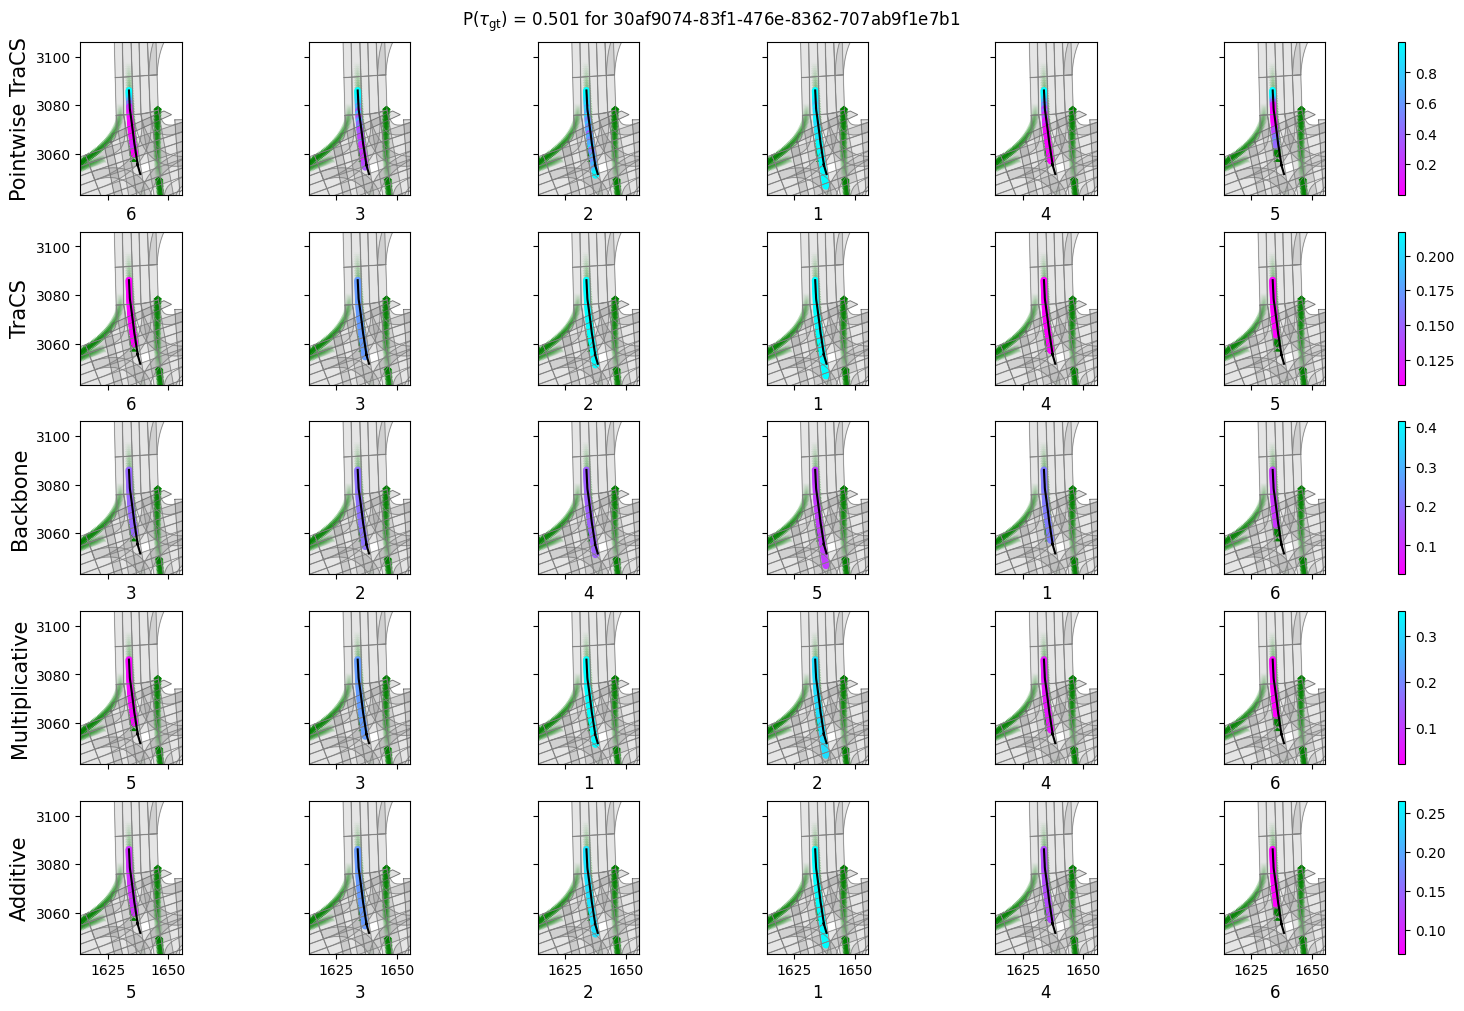

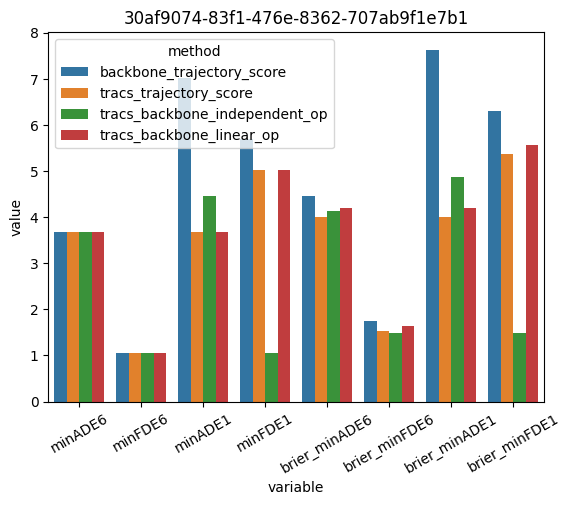

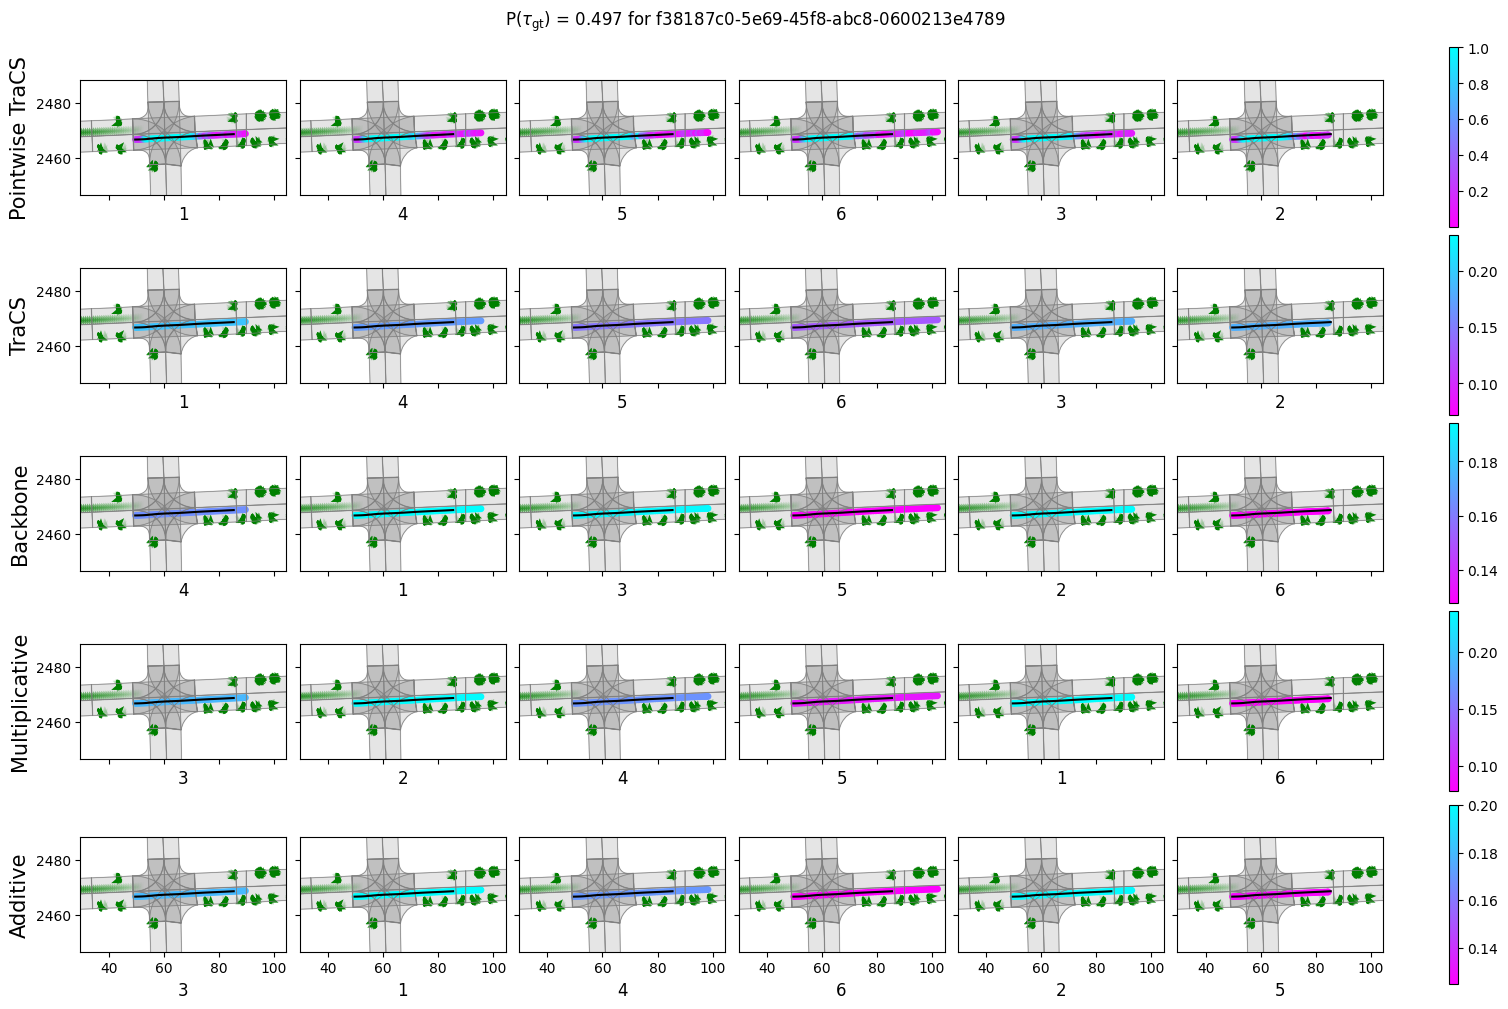

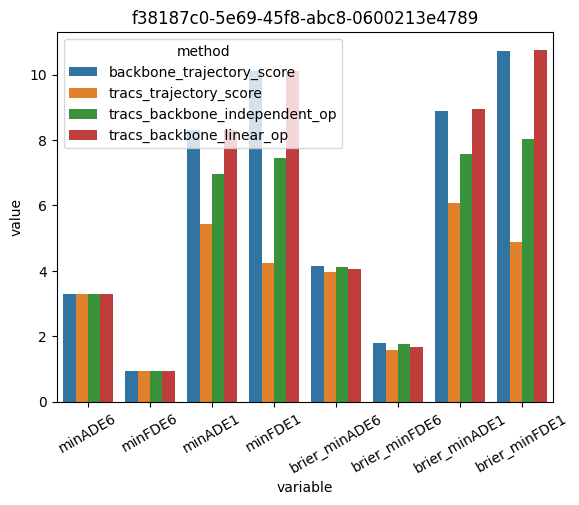

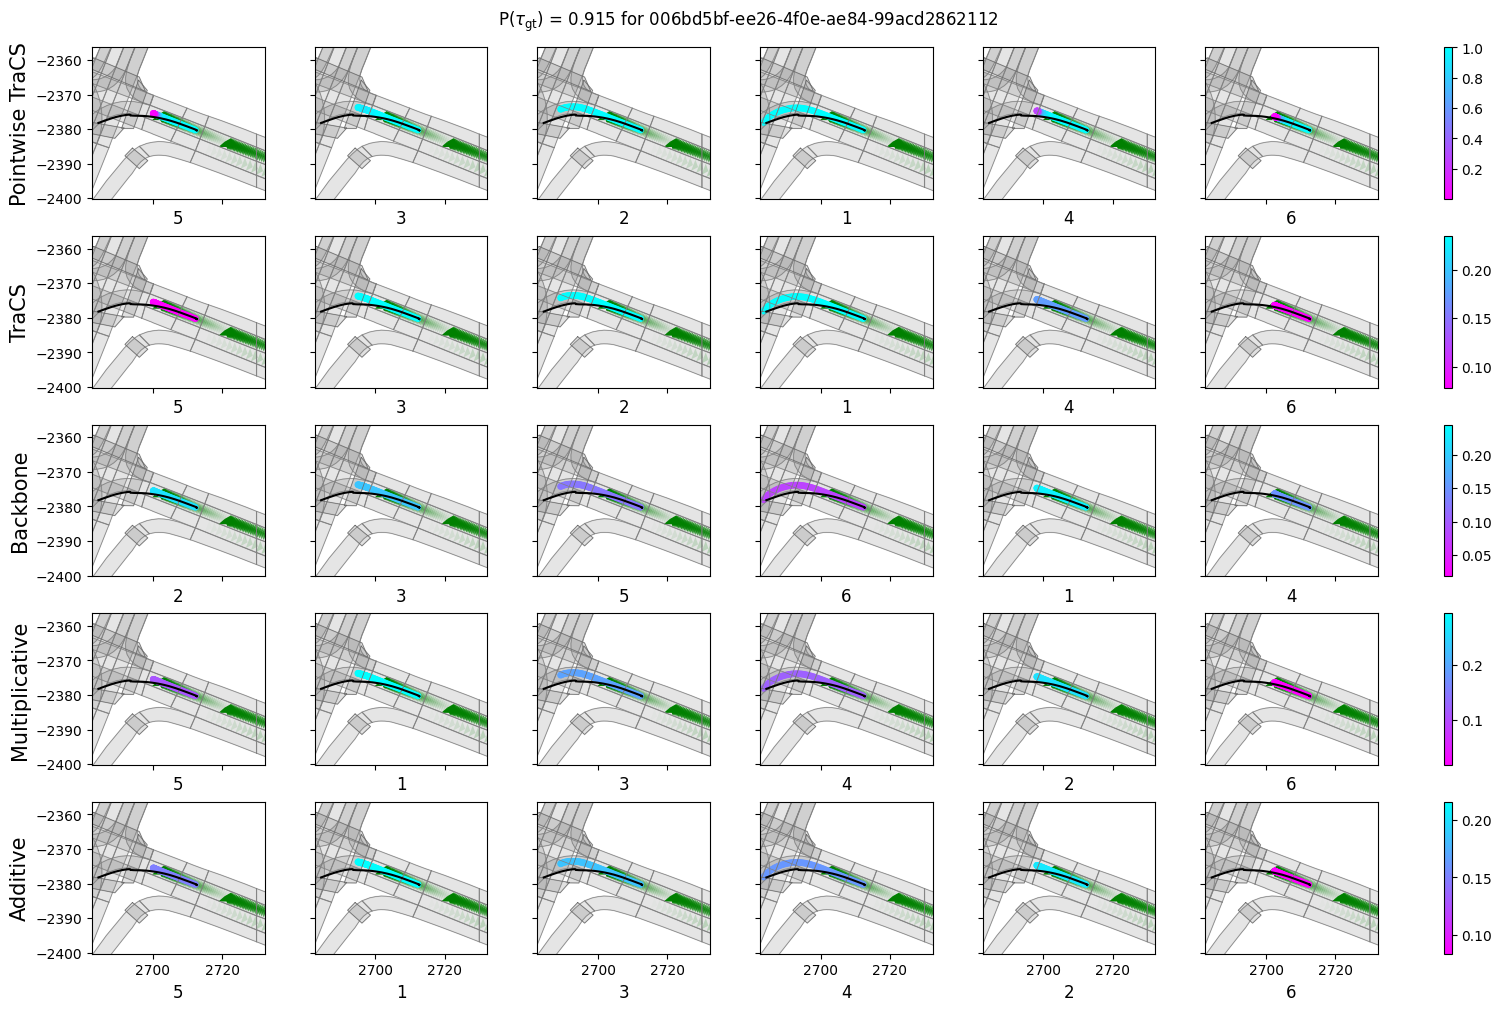

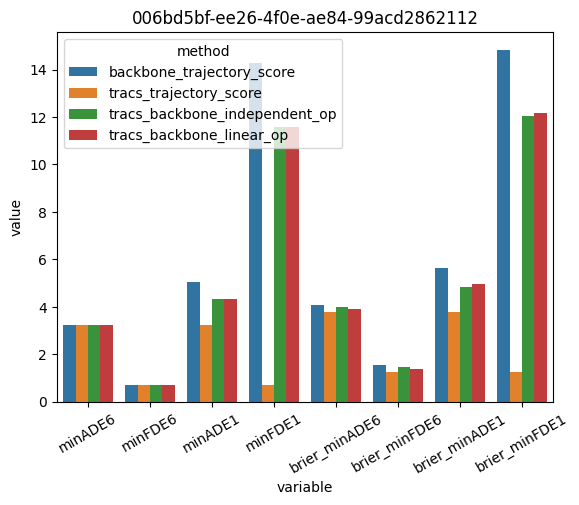

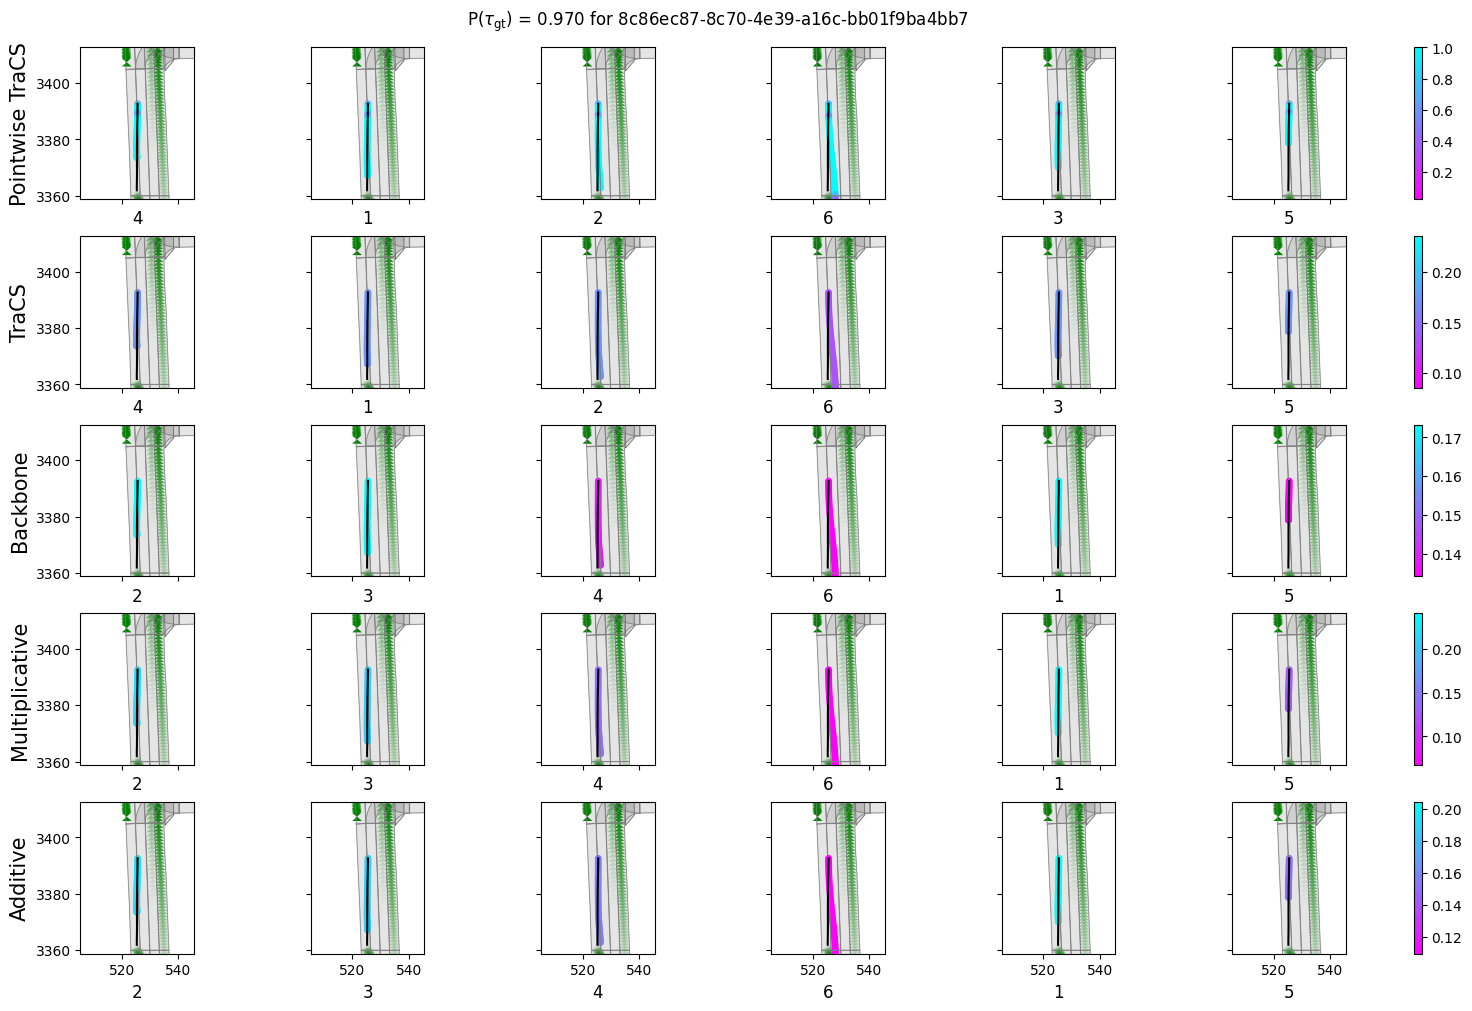

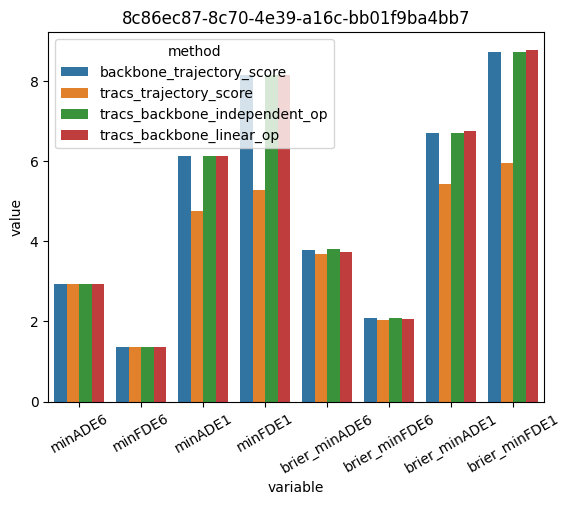

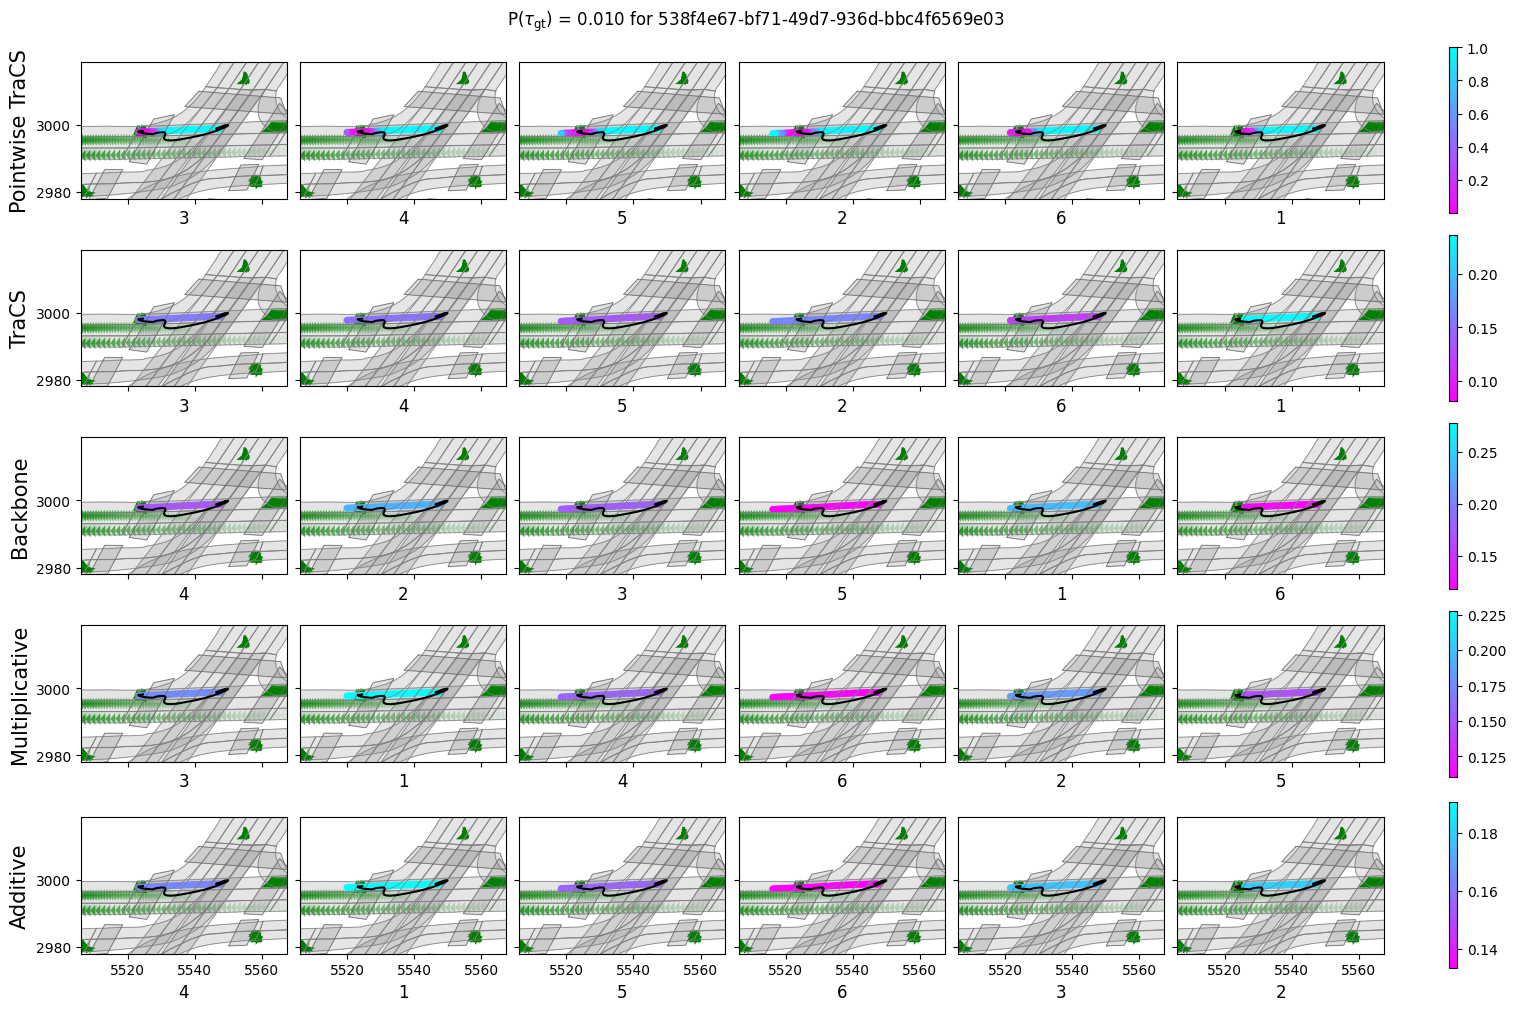

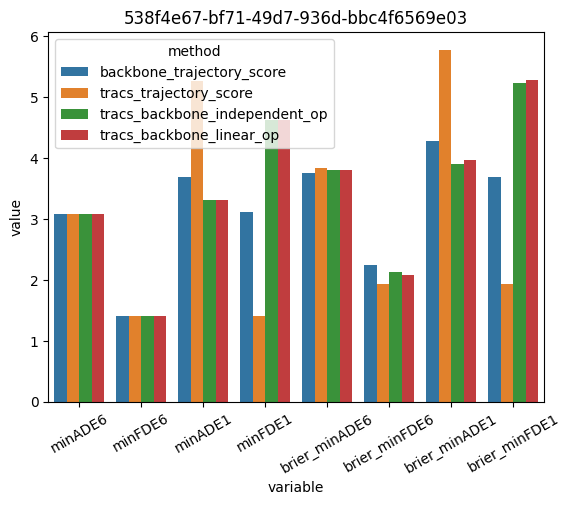

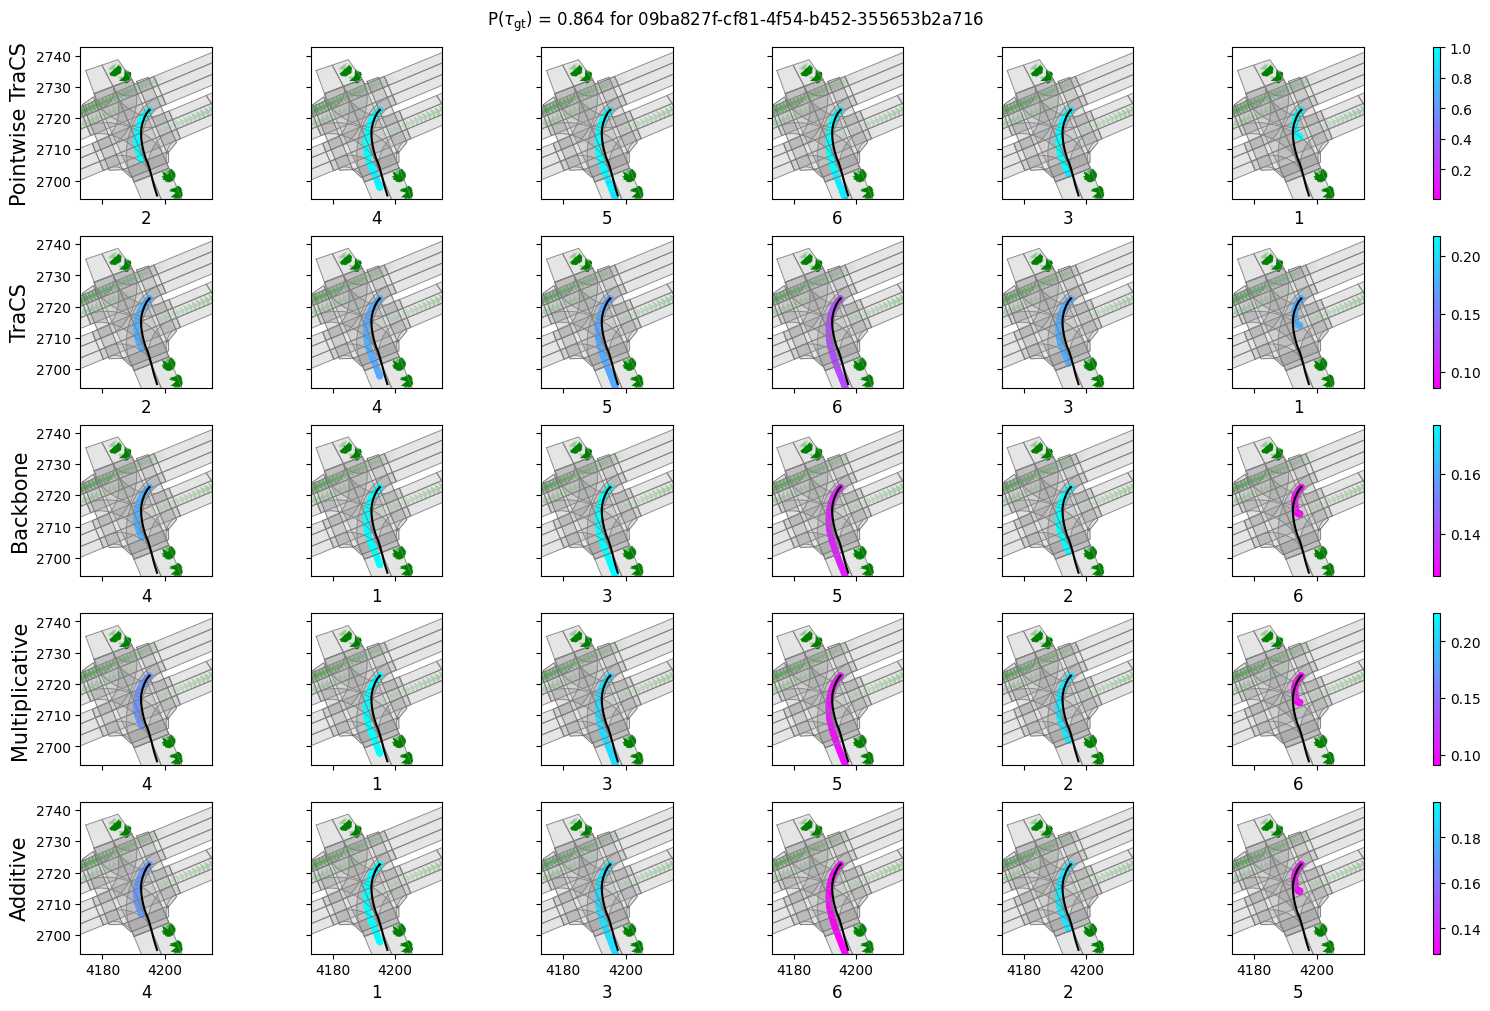

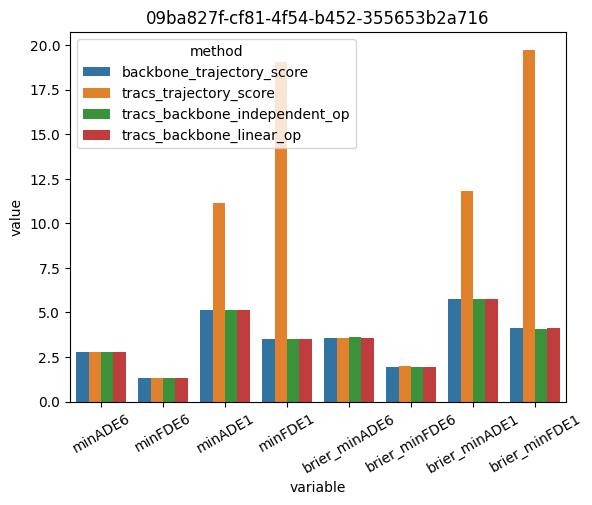

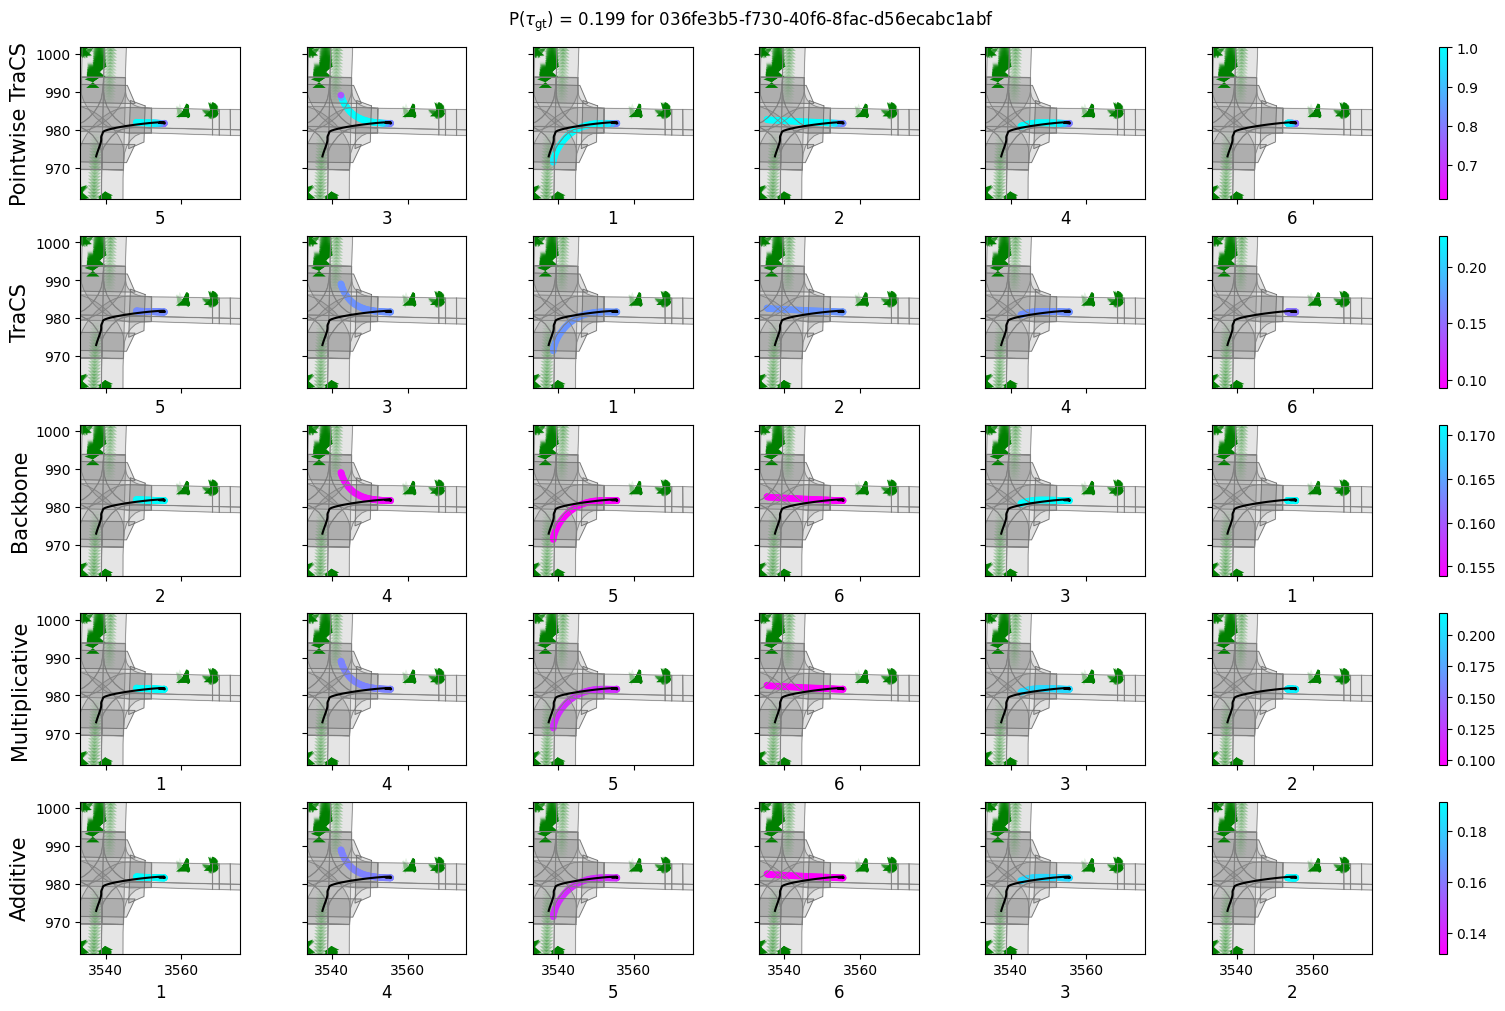

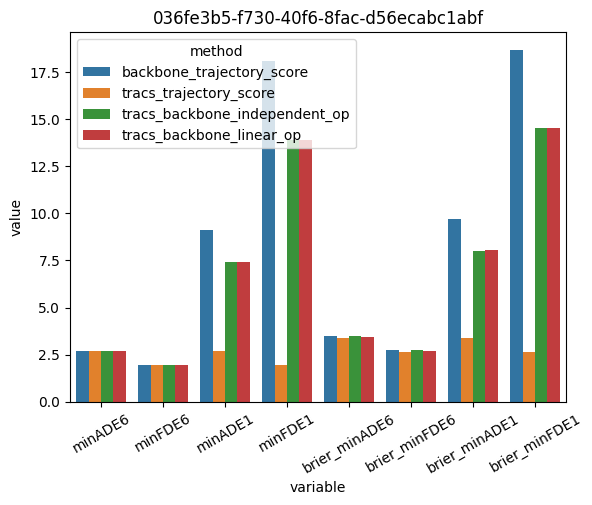

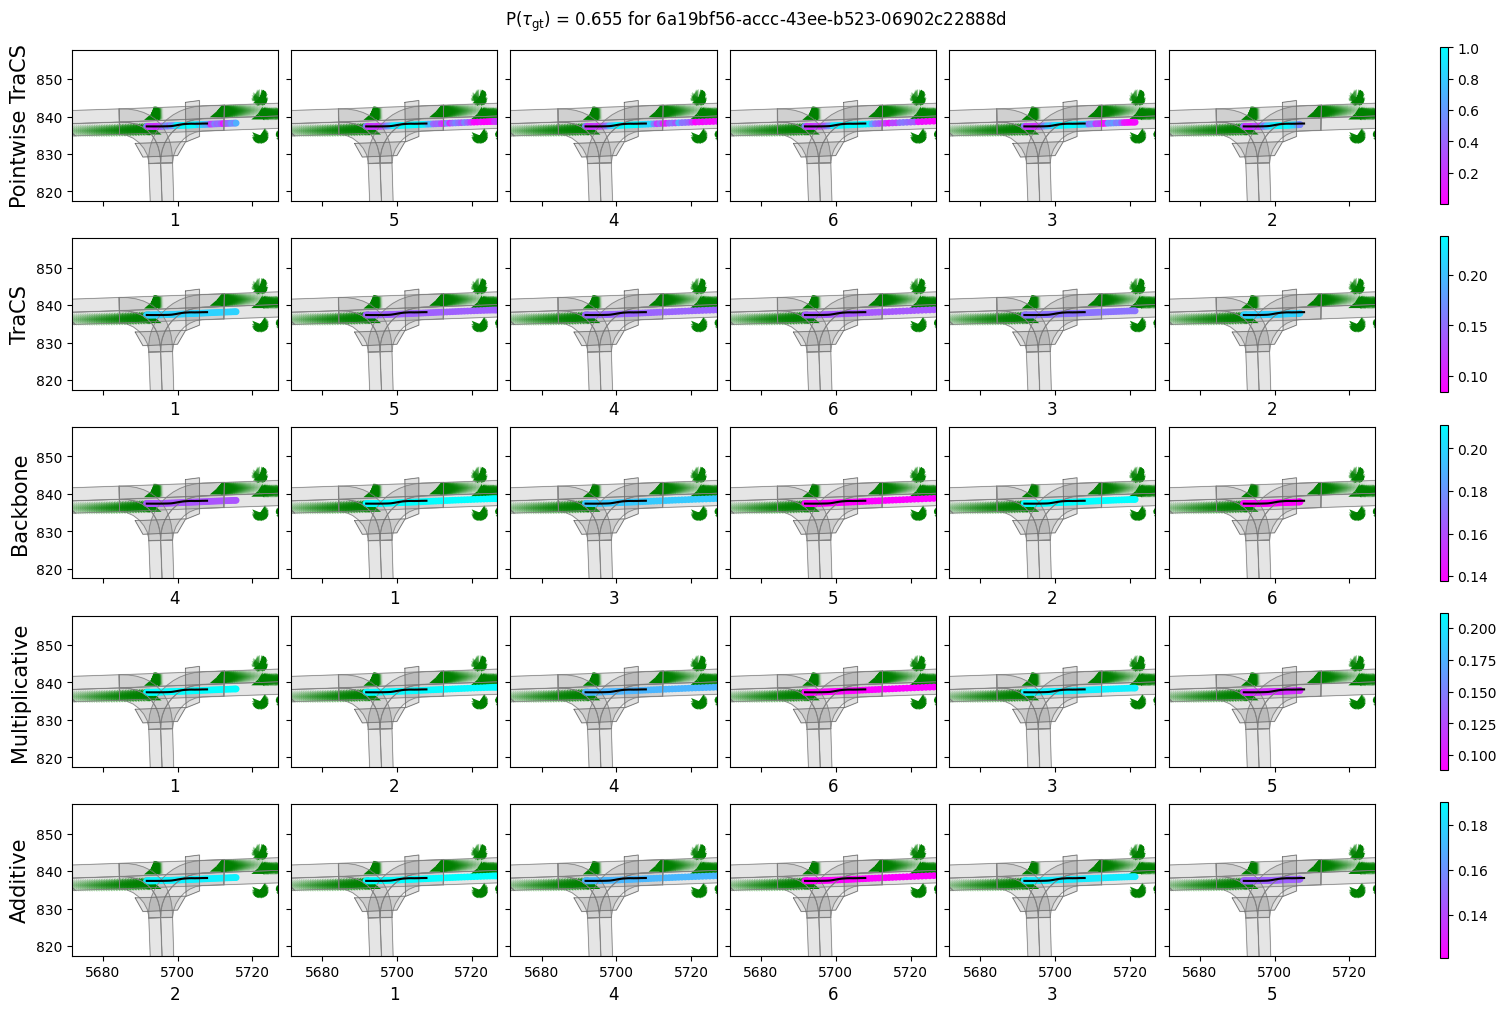

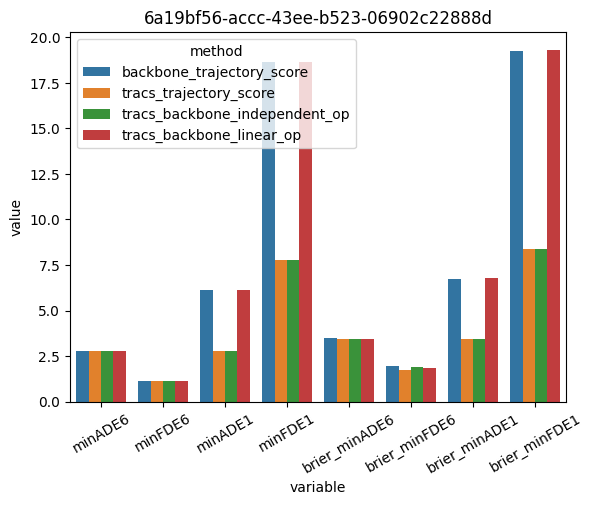

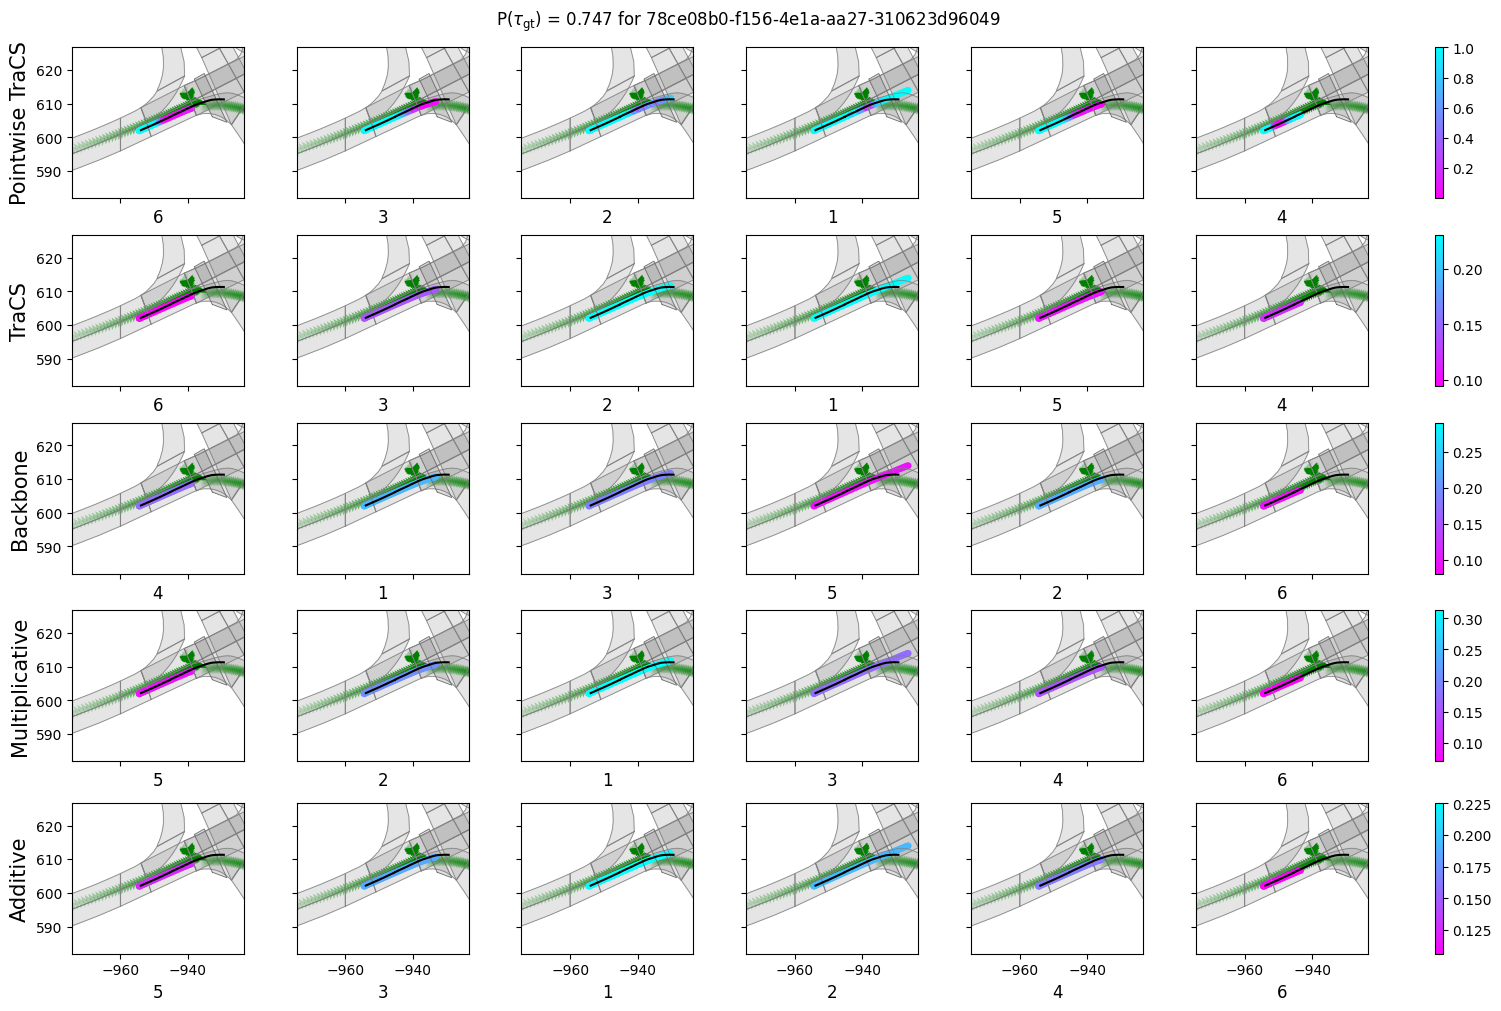

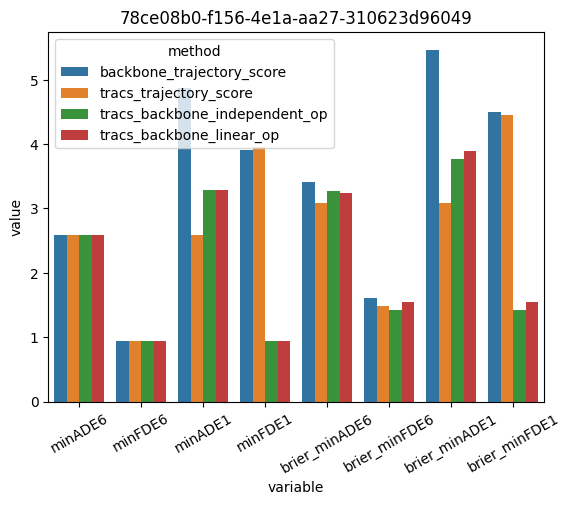

In [3]:

# logic = """
# distance(vehicle) <- source("/star_map/distance/vehicle", Density).
# speed <- source("/sensors/speed", Number).
# over(intersection) <- source("/star_map/over/intersection", Probability).

# # Define three speed levels for city driving with corresponding safe distances
# low_speed if speed < 20.
# medium_speed if speed > 20 and speed < 40.
# high_speed if speed > 40.

# # Safe distance requirements for each speed level
# safe_at_low if low_speed and distance(vehicle) > 5.
# safe_at_medium if medium_speed and distance(vehicle) > 10.
# safe_at_high if high_speed and distance(vehicle) > 20.

# # Landscape: safe distance must be maintained according to speed level
# landscape if safe_at_low.
# landscape if safe_at_medium.
# landscape if safe_at_high.
# landscape if not over(intersection).

# landscape -> target("/landscape").
# """

logic = """
distance(vehicle) <- source("/star_map/distance/vehicle", Density).
speed <- source("/sensors/speed", Number).

landscape if distance(vehicle) > 5 and speed < 50.

landscape -> target("/landscape").
"""

for i in range(10):
    scenario_id = worst.iloc[i]["scenario_id"]
    scored_predictions, gt_score = tracs_rate_scenario(
        scenario_id=scenario_id,
        logic=logic,
        prediction_path=prediction_path,
        data_root=data_root,
        mode="test",
    )
    show_comparison_study(scored_predictions, gt_score, data_root, backbone, "test", scenario_id)
    
    metrics = compute_argoverse2_metrics(scored_predictions, data_root, scenario_id)
    melted = metrics.melt("method")
    melted = melted[melted["variable"] != "scenario_id"]
    melted = melted[melted["variable"] != "track_id"]
    melted = melted[melted["variable"] != "is_missed_prediction6"]
    melted = melted[melted["variable"] != "is_missed_prediction1"]

    plt.title(f"{scenario_id}")
    sns.barplot(melted, x="variable", y="value", hue="method")
    plt.xticks(rotation=30)
    plt.show()